<a href="https://colab.research.google.com/github/Zafeerxyz/Machine-Learning-algorithms/blob/main/DBScan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import kagglehub
path = kagglehub.dataset_download("vjchoudhary7/customer-segmentation-tutorial-in-python")

Using Colab cache for faster access to the 'customer-segmentation-tutorial-in-python' dataset.


In [ ]:
import pandas as pd

# Load the dataset (replace 'Mall_Customers.csv' with your actual file name)
df = pd.read_csv(f"{path}/Mall_Customers.csv")

# Display the first few rows
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
from sklearn.preprocessing import StandardScaler


X = df[['Annual Income (k$)', 'Spending Score (1-100)']]

scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.4,
                min_samples=5)
labels = dbscan.fit_predict(X_scaled)

df["DBSCAN_Cluster"] = labels

In [ ]:
import numpy as np

unique_labels, counts = np.unique(labels, return_counts=True)

for label, count in zip(unique_labels, counts):
    print(f"Cluster {label}: {count} customers")

Cluster -1: 15 customers
Cluster 0: 115 customers
Cluster 1: 11 customers
Cluster 2: 32 customers
Cluster 3: 27 customers


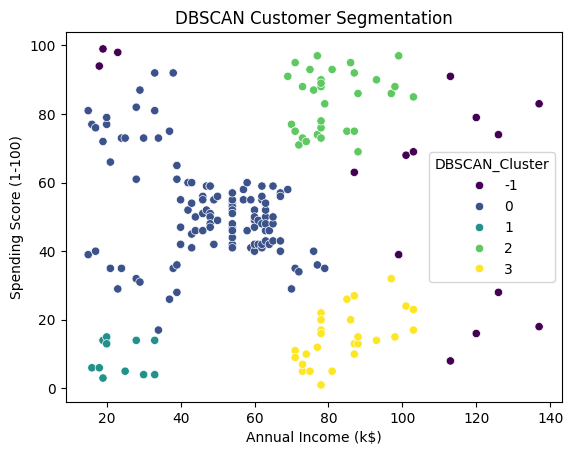

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt

sns.scatterplot(
    data=df,
    x='Annual Income (k$)',
    y='Spending Score (1-100)',
    hue='DBSCAN_Cluster',
    palette='viridis'
)

plt.title("DBSCAN Customer Segmentation")
plt.show()

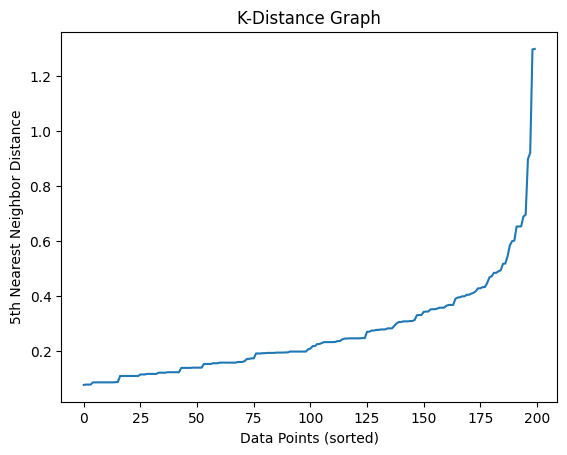

In [ ]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

neighbors = NearestNeighbors(n_neighbors=5)
neighbors_fit = neighbors.fit(X_scaled)

distances, indices = neighbors_fit.kneighbors(X_scaled)

k_distances = np.sort(distances[:, 4])

plt.plot(k_distances)
plt.xlabel("Data Points (sorted)")
plt.ylabel("5th Nearest Neighbor Distance")
plt.title("K-Distance Graph")
plt.show()

In [ ]:
from sklearn.cluster import DBSCAN
import numpy as np

for eps in [0.35, 0.40, 0.45, 0.50, 0.55]:

    model = DBSCAN(
        eps=eps,
        min_samples=5
    )

    labels = model.fit_predict(X_scaled)

    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise = np.sum(labels == -1)

    print(
        f"eps={eps}: "
        f"Clusters={n_clusters}, "
        f"Noise={noise}"
    )

eps=0.35: Clusters=6, Noise=23
eps=0.4: Clusters=4, Noise=15
eps=0.45: Clusters=3, Noise=11
eps=0.5: Clusters=2, Noise=8
eps=0.55: Clusters=1, Noise=7
